# Chapitre 8 - Cours 1 : bootstrap, maximum de vraisemblance et approche bayésienne

Ce premier notebook couvre les sections 8.1 à 8.4 du livre. Jusqu'ici, la plupart des
modèles ont été ajustés en minimisant une somme de carrés (régression) ou une
entropie croisée (classification). Ces deux minimisations sont en fait des cas
particuliers d'un principe général : le **maximum de vraisemblance**.

Nous allons :

1. reprendre l'exemple de lissage par B-splines du livre (figures 8.1 et 8.2) ;
2. mesurer l'incertitude de l'ajustement de trois façons : formule des moindres carrés,
   **bootstrap non paramétrique**, **bootstrap paramétrique** ;
3. rappeler la théorie du **maximum de vraisemblance** (score, information de Fisher,
   normalité asymptotique, intervalles fondés sur la vraisemblance) ;
4. présenter l'**approche bayésienne** sur le même exemple (figures 8.3 et 8.4) ;
5. expliquer pourquoi le bootstrap est une sorte de « loi a posteriori du pauvre »
   (section 8.4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. L'exemple de lissage (section 8.2.1)

On dispose de $N = 50$ couples $z_i = (x_i, y_i)$ avec $x_i \in [0, 3]$ et $y_i$ réel.
Les 50 points exacts du livre ne sont pas publiés ; nous **simulons** donc un jeu de
données de même allure :

$$x_i \sim \mathcal U[0,3], \qquad y_i = \mu(x_i) + \varepsilon_i, \qquad
\mu(x) = 1 + 1{,}6\,\sin(2{,}6\,x + 0{,}9), \qquad \varepsilon_i \sim N(0, 0{,}9^2).$$

La fonction $\mu$ est bien sûr inconnue du statisticien : elle ne sert qu'à fabriquer les
données et, plus loin, à juger les méthodes.

In [2]:
N = 50
x = np.sort(rng.uniform(0, 3, N))
mu_true = lambda t: 1 + 1.6 * np.sin(2.6 * t + 0.9)
y = mu_true(x) + 0.9 * rng.randn(N)
x_grid = np.linspace(0, 3, 300)

### Base de B-splines cubiques

On choisit d'ajuster une **spline cubique** (polynôme de degré 3 par morceaux, de classe
$C^2$) avec trois nœuds intérieurs placés aux quartiles des $x_i$. L'ensemble de ces
fonctions est un espace vectoriel de dimension $3 + 4 = 7$ (nombre de nœuds intérieurs
+ degré + 1, voir chapitre 5). On en choisit une base commode, les **B-splines**
$h_1, \dots, h_7$ (section 5.9.2 du livre) :

$$\mu(x) = \sum_{j=1}^{7} \beta_j\, h_j(x). \qquad \text{(éq. (8.1) du livre)}$$

Chaque $h_j$ est positive, nulle en dehors de quatre intervalles consécutifs, et les
$h_j$ somment à 1 en tout point (« partition de l'unité »).

In [3]:
interior = np.quantile(x, [0.25, 0.5, 0.75])
knots = inf.bspline_knots(interior, (0, 3))
H = inf.bspline_basis(x, knots)            # matrice N x 7 : H[i, j] = h_j(x_i)
H_grid = inf.bspline_basis(x_grid, knots)
print("Dimensions de H :", H.shape)
print("Somme des h_j sur la grille : min = %.6f, max = %.6f"
      % (H_grid.sum(1).min(), H_grid.sum(1).max()))

Dimensions de H : (50, 7)
Somme des h_j sur la grille : min = 1.000000, max = 1.000000


**Figure 8.1.** À gauche, les données ; à droite, les sept fonctions de base, avec les
trois nœuds en pointillés.

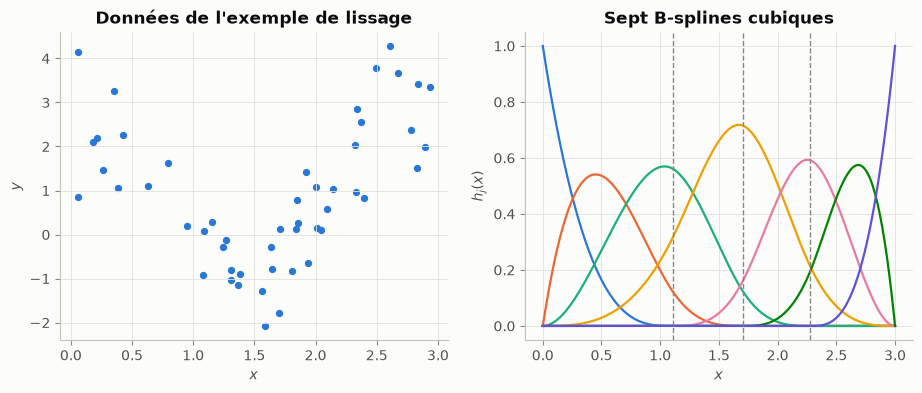

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, color=BLUE, s=18)
ax[0].set(title="Données de l'exemple de lissage", xlabel="$x$", ylabel="$y$")
for j in range(H_grid.shape[1]):
    ax[1].plot(x_grid, H_grid[:, j], color=COLORS[j % len(COLORS)], lw=1.6)
for k in interior:
    ax[1].axvline(k, color=GRAY, ls="--", lw=1)
ax[1].set(title="Sept B-splines cubiques", xlabel="$x$", ylabel="$h_j(x)$")
plt.show()

## 2. Ajustement par moindres carrés et erreurs standard

Notons $H$ la matrice $N \times 7$ d'élément $H_{ij} = h_j(x_i)$. L'estimateur des
moindres carrés minimise $\|y - H\beta\|^2$ ; en annulant le gradient $-2H^T(y - H\beta)$
on obtient les équations normales $H^TH\beta = H^Ty$, d'où (car $H^TH$ est inversible,
les colonnes de $H$ étant linéairement indépendantes) :

$$\hat\beta = (H^TH)^{-1}H^Ty. \qquad \text{(éq. (8.2))}$$

La courbe ajustée est $\hat\mu(x) = \sum_j \hat\beta_j h_j(x) = h(x)^T\hat\beta$ où
$h(x)^T = (h_1(x), \dots, h_7(x))$.

In [5]:
beta_hat, sigma2_hat, cov_beta = inf.ls_fit(H, y)
mu_hat = H_grid @ beta_hat
print("beta_hat =", np.round(beta_hat, 3))
print("sigma2_hat = %.3f   (vraie variance du bruit : %.3f)" % (sigma2_hat, 0.9 ** 2))

beta_hat = [ 2.229  2.743 -0.141 -1.447  2.264  4.096  1.781]
sigma2_hat = 0.617   (vraie variance du bruit : 0.810)


### Variance de $\hat\beta$ et de $\hat\mu(x)$

Les $x_i$ étant considérés comme fixés, $y$ a pour matrice de covariance $\sigma^2 I_N$.
Comme $\hat\beta = Ay$ avec $A = (H^TH)^{-1}H^T$, on a
$\mathrm{Var}(\hat\beta) = A(\sigma^2 I)A^T = \sigma^2 (H^TH)^{-1}H^TH(H^TH)^{-1}
= \sigma^2(H^TH)^{-1}$. En remplaçant $\sigma^2$ par
$\hat\sigma^2 = \frac1N\sum_i (y_i - \hat\mu(x_i))^2$ :

$$\widehat{\mathrm{Var}}(\hat\beta) = (H^TH)^{-1}\hat\sigma^2. \qquad \text{(éq. (8.3))}$$

Puis, $\hat\mu(x) = h(x)^T\hat\beta$ étant une combinaison linéaire de $\hat\beta$,
$\mathrm{Var}(\hat\mu(x)) = h(x)^T \mathrm{Var}(\hat\beta) h(x)$, d'où l'erreur standard

$$\widehat{\mathrm{se}}[\hat\mu(x)] = \big[h(x)^T(H^TH)^{-1}h(x)\big]^{1/2}\,\hat\sigma.
\qquad \text{(éq. (8.4))}$$

Comme 1,96 est le quantile à 97,5 % de la loi $N(0,1)$, la bande
$\hat\mu(x) \pm 1{,}96\,\widehat{\mathrm{se}}[\hat\mu(x)]$ est une bande de confiance
**ponctuelle** approximativement à 95 %.

In [6]:
se_ls = inf.pointwise_se(H_grid, cov_beta)
lo_ls, hi_ls = mu_hat - 1.96 * se_ls, mu_hat + 1.96 * se_ls